In [35]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
import os
from tqdm import tqdm

In [36]:
rebecca_data_ir = pd.read_csv('processed_data_new/rebecca_data_ir_final.csv')
del rebecca_data_ir['Unnamed: 0']
rebecca_data_ir.columns = list(np.float64(rebecca_data_ir.columns[:-4])) + list(rebecca_data_ir.columns[-4:])

rebecca_data_raman = pd.read_csv('processed_data_new/rebecca_data_raman_final_als.csv')
del rebecca_data_raman['Unnamed: 0']
rebecca_data_raman.columns = list(np.float64(rebecca_data_raman.columns[:-4])) + list(rebecca_data_raman.columns[-4:])

In [37]:
rebecca_data_raman.shape, rebecca_data_ir.shape

((388, 1577), (349, 539))

In [38]:
np.unique(rebecca_data_raman['polymer'])

array(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'], dtype=object)

In [39]:
poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

IR_spectra_mix_std = pd.read_csv('processed_data_new/data_ir_mix_std_rebecca.csv')
del IR_spectra_mix_std['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix_std.columns = list(np.float64(IR_spectra_mix_std.columns[:-8])) + list(IR_spectra_mix_std.columns[-8:])

IR_spectra_mix_std = (IR_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix_std.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_std_rest = IR_spectra_mix_std.loc[[x not in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std.loc[IR_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix_std = IR_spectra_mix_std.sort_values('id').reset_index(drop=True)


#Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca.csv')
Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca_als.csv')
#notes_mix_std_rest = np.array(Raman_spectra_mix_std['comments'])
notes_mix_std = Raman_spectra_mix_std.iloc[:,-5:]

notes_mix_std = (notes_mix_std.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix_std.loc[notes_mix_std['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_std_rest[[x is np.nan for x in notes_mix_std_rest]] = ''
del Raman_spectra_mix_std['Unnamed: 0']
Raman_spectra_mix_std.columns = list(np.float64(Raman_spectra_mix_std.columns[:-7])) + list(Raman_spectra_mix_std.columns[-7:])
Raman_spectra_mix_std = (Raman_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix_std.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.sort_values('id').reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_std_rest = Raman_spectra_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
notes_mix_std_rest = notes_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

Raman_spectra_mix_std.loc[Raman_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'

#ids_ideal_set = [(x in poly_list) and (y in poly_list) and (z in poly_list) for x, y, z in zip(notes_mix_std['polymer_raman'], notes_mix_std['polymer_ir'], notes_mix_std['polymer_overall'])]
#Raman_spectra_mix_std = Raman_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)


In [40]:
notes_mix_std_rest.groupby('polymer_overall').count()

,comments,id,polymer_raman,polymer_ir
polymer_overall,,,,
LOW SIGNAL,1,107,107,107
MIXTURE,44,44,44,44
UNSORTED,53,54,54,54


In [41]:
notes_mix_std.groupby('polymer_overall').count()

,comments,id,polymer_raman,polymer_ir
polymer_overall,,,,
NH2SO4,3,45,45,45
NaNO3,2,13,13,13
PE,3,38,38,38
PP,0,4,4,4
PSL,5,13,13,13
sucrose,21,111,111,111


In [42]:
notes_mix_std_rest.groupby('polymer_raman').count()

,comments,id,polymer_overall,polymer_ir
polymer_raman,,,,
LOW SIGNAL,2,108,108,108
MIXTURE,43,43,43,43
NH2SO4,1,1,1,1
PE,2,2,2,2
PSL,5,5,5,5
UNSORTED,32,33,33,33
sucrose,13,13,13,13


In [43]:
notes_mix_std_rest.groupby('polymer_ir').count()

,comments,id,polymer_overall,polymer_raman
polymer_ir,,,,
LOW SIGNAL,22,128,128,128
MIXTURE,34,34,34,34
NH2SO4,6,6,6,6
PE,2,2,2,2
PP,1,1,1,1
PSL,1,1,1,1
UNSORTED,30,31,31,31
sucrose,2,2,2,2


In [44]:
IR_spectra_mix = pd.read_csv('processed_data_new/data_ir_mix_rebecca.csv')
del IR_spectra_mix['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix.columns = list(np.float64(IR_spectra_mix.columns[:-5])) + list(IR_spectra_mix.columns[-5:])
IR_spectra_mix_rest = IR_spectra_mix.loc[[x not in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix = IR_spectra_mix.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix.loc[IR_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'

Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca_als.csv')
del Raman_spectra_mix['Unnamed: 0']
Raman_spectra_mix.columns = list(np.float64(Raman_spectra_mix.columns[:-4])) + list(Raman_spectra_mix.columns[-4:])
Raman_spectra_mix_rest = Raman_spectra_mix.loc[[x not in ['LDPE', 'PP', 'PSL'] for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.loc[[x in ['LDPE', 'PP', 'PSL'] for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
Raman_spectra_mix.loc[Raman_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'


In [45]:
IR_spectra_amb = pd.read_csv('processed_data_new/data_ir_amb_rebecca.csv')
del IR_spectra_amb['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_amb.columns = list(np.float64(IR_spectra_amb.columns[:-8])) + list(IR_spectra_amb.columns[-8:])
IR_spectra_amb_rest = IR_spectra_amb.loc[[x not in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_amb['polymer']],:].reset_index(drop=True)
#IR_spectra_amb = IR_spectra_amb.loc[[x in ['LDPE', 'PP', 'PSL', 'AMB'] for x in IR_spectra_amb['polymer']],:].reset_index(drop=True)
IR_spectra_amb = IR_spectra_amb.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_amb['polymer']],:].reset_index(drop=True)
IR_spectra_amb.loc[IR_spectra_amb['polymer'] == 'LDPE','polymer'] = 'PE'

Raman_spectra_amb = pd.read_csv('processed_data_new/data_raman_amb_rebecca_als.csv')
del Raman_spectra_amb['Unnamed: 0']
Raman_spectra_amb.columns = list(np.float64(Raman_spectra_amb.columns[:-7])) + list(Raman_spectra_amb.columns[-7:])
Raman_spectra_amb_rest = Raman_spectra_amb.loc[[x not in ['LDPE', 'PP', 'PSL'] for x in Raman_spectra_amb['polymer']],:].reset_index(drop=True)
#Raman_spectra_amb = Raman_spectra_amb.loc[[x in ['LDPE', 'PP', 'PSL', 'AMB'] for x in Raman_spectra_amb['polymer']],:].reset_index(drop=True)
Raman_spectra_amb = Raman_spectra_amb.loc[[x in ['LDPE', 'PP', 'PSL'] for x in Raman_spectra_amb['polymer']],:].reset_index(drop=True)
Raman_spectra_amb.loc[Raman_spectra_amb['polymer'] == 'LDPE','polymer'] = 'PE'


In [46]:
def process_data(rebecca_data_ir, rebecca_data_raman, IR_spectra, Raman_spectra, range_r=[550, 3500]):
    
    #range_r = [550, 3500] 
    
    wn_rb = np.array(rebecca_data_ir.columns[:-4])
    idx_rb = list(np.logical_or(np.logical_and(wn_rb > 980, wn_rb < 1800),
                           np.logical_and(wn_rb > 2720, wn_rb < 2950)
                          ) ) + [False]*4
    
    wn_rb_r = np.array(rebecca_data_raman.columns[:-4])
    idx_rb_r = list(np.logical_and(wn_rb_r > range_r[0], wn_rb_r < range_r[1])) + [False]*4


    wn_rb_amb = np.array(IR_spectra.columns[:-8])
    idx_rb_amb = list(np.logical_or(np.logical_and(wn_rb_amb > 980, wn_rb_amb < 1800),
                           np.logical_and(wn_rb_amb > 2720, wn_rb_amb < 2950) #2993.64990234375-10
                          ) ) + [False]*8
    
    wn_rb_amb_r = np.array(Raman_spectra.columns[:-4])
    idx_rb_amb_r = list(np.logical_and(wn_rb_amb_r > range_r[0], wn_rb_amb_r < range_r[1])) + [False]*4
    
    x_train_ir = rebecca_data_ir.iloc[:,idx_rb].to_numpy()
    x_train_ir = (x_train_ir - x_train_ir.mean(1)[:, None]) / x_train_ir.std(1)[:, None]
    
    y_train_ir = rebecca_data_ir.iloc[:,-2]

    x_train_raman = rebecca_data_raman.iloc[:,idx_rb_r].to_numpy()
    x_train_raman = (x_train_raman - x_train_raman.mean(1)[:, None]) / x_train_raman.std(1)[:, None]
    
    y_train_raman = rebecca_data_raman.iloc[:,-2]

    x_ir = IR_spectra.iloc[:,idx_rb_amb].to_numpy()
    x_ir = (x_ir - x_ir.mean(1)[:, None]) / x_ir.std(1)[:, None]    

    x_raman = Raman_spectra.iloc[:,idx_rb_amb_r].to_numpy()
    x_raman = (x_raman - x_raman.mean(1)[:, None]) / x_raman.std(1)[:, None]
    y_test = IR_spectra.iloc[:,-3]
    
    idx_test = np.sum(np.isnan(x_raman), axis=1) == 0
    
    x_ir = x_ir[idx_test,:]
    x_raman = x_raman[idx_test,:]
    
    y_raman = y_test[idx_test]
    y_ir = y_test[idx_test]
    
    #y_test[y_test == 'LDPE'] = 'PE'
    
    poly_list = list(np.unique(np.concatenate([y_train_ir, y_train_raman, y_ir]))) 
    label_table = pd.DataFrame({'label':np.arange(len(poly_list)), 'polymer':poly_list})
    
    label_train_Raman = np.array(pd.DataFrame(y_train_raman).merge(label_table, left_on="polymer", right_on="polymer")['label'])
    label_train_IR = np.array(pd.DataFrame(y_train_ir).merge(label_table, left_on="polymer", right_on="polymer")['label'])
    
    label_ir = np.array(pd.DataFrame(y_ir).merge(label_table, how='left', left_on="polymer", right_on="polymer")['label'])
    
    label_raman = np.array(pd.DataFrame(y_raman).merge(label_table, how='left', left_on="polymer", right_on="polymer")['label'])
    
    return x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table


In [47]:
def process_data_2(IR_spectra, Raman_spectra, range_r=[550, 3500]):
    
    #range_r = [550, 3500] 


    wn_rb_amb = np.array(IR_spectra.columns[:-8])
    idx_rb_amb = list(np.logical_or(np.logical_and(wn_rb_amb > 980, wn_rb_amb < 1800),
                           np.logical_and(wn_rb_amb > 2720, wn_rb_amb < 2950) #2993.64990234375-10
                          ) ) + [False]*8
    
    wn_rb_amb_r = np.array(Raman_spectra.columns[:-4])
    idx_rb_amb_r = list(np.logical_and(wn_rb_amb_r > range_r[0], wn_rb_amb_r < range_r[1])) + [False]*4

    x_ir = IR_spectra.iloc[:,idx_rb_amb].to_numpy()
    x_ir = (x_ir - x_ir.mean(1)[:, None]) / x_ir.std(1)[:, None]    

    x_raman = Raman_spectra.iloc[:,idx_rb_amb_r].to_numpy()
    x_raman = (x_raman - x_raman.mean(1)[:, None]) / x_raman.std(1)[:, None]

    y_test = IR_spectra.iloc[:,-3]
    #y_test[y_test == 'LDPE'] = 'PE'
    
    return x_ir, x_raman, y_test

In [48]:
def experiment(score_list, label_ir, alphas, N_sim, seed=0):
    df_res_lis = []
    df_res_sd_lis = []
    df_res_all_lis = []
    df_res_cov_lis = []
    df_res_cov_sd_lis = []

    for alpha in tqdm(alphas):
        set_size = defaultdict(list)
        set_size_all = defaultdict(list)
        zero_sets = defaultdict(list)
        cov = defaultdict(list)
        cov_cal = defaultdict(list)
        set_size_by_label_hqi = defaultdict(list)
        K = 2
        U_list = gen_u(K, seed=0)
        for l in range(N_sim):
            seed = seed + l

            #score_list, y_train, y_test, top_views = simulate_s_2(N, d, d_v, L, scale, K, N_train, seed)
            #top_views = np.array(acc_list)
            quant_smx_list = []
            rest_smx_list = []
            cal_smx_list = []
            val_smx_list = []


            for i in range(K):

                quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
                #print(quant_smx.shape, rest_smx.shape)
                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=0.8, seed=seed)
                #print(cal_smx.shape, val_smx.shape)

                quant_smx_list.append(quant_smx)
                rest_smx_list.append(rest_smx)
                cal_smx_list.append(cal_smx)
                val_smx_list.append(val_smx)

            n = cal_labels.shape[0]

            for j in range(1,K):

                prediction_sets, empirical_coverage = mvcp_2(quant_smx_list[:(j+1)],
                                                             quant_labels,
                                                             cal_smx_list[:(j+1)], 
                                                             cal_labels, 
                                                             val_smx_list[:(j+1)], 
                                                             alpha, 
                                                             val_labels, 
                                                             U=U_list[0])

                #prediction_sets, empirical_coverage = mvcp(quant_smx_list[0],
                #                                           quant_smx_list[1],
                #                                             quant_labels,
                #                                             cal_smx_list[0], 
                #                                           val_smx_list[0], 
                #                                          cal_smx_list[1], 
                #                                          val_smx_list[1], 
                #                                          cal_labels, 
                #                                            alpha, 
                #                                            val_labels)
                


                set_size['mvcp'+str(j+1)].append(
                    prediction_sets.sum(1).mean()
                )
                set_size_all['mvcp'+str(j+1)].append(
                    prediction_sets.sum(1)
                )
                zero_sets['mvcp'+str(j+1)].append(
                    np.mean(prediction_sets.sum(1) == 0)
                )
                cov['mvcp'+str(j+1)].append(
                    empirical_coverage
                )

                set_size_by_label_hqi['mvcp'+str(j+1)].append(
                    pd.DataFrame({'label':val_labels, 
                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
                )

                s_u = rest_smx_list[:(j+1)][0]
                #print(top_views[:(j+1)])
                #print(np.argmax(top_views[:(j+1)]))

                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
                n = cal_smx.shape[0]
                (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
                set_size['view_IR'+str(j+1)].append(prediction_sets.sum(1).mean())

                set_size_all['view_IR'+str(j+1)].append(
                    prediction_sets.sum(1)
                )

                zero_sets['view_IR'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
                cov['view_IR'+str(j+1)].append(empirical_coverage)

                set_size_by_label_hqi['view_IR'+str(j+1)].append(
                    pd.DataFrame({'label':val_labels, 
                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
                )

                s_u = rest_smx_list[:(j+1)][1]
                #print(top_views[:(j+1)])
                #print(np.argmax(top_views[:(j+1)]))

                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
                n = cal_smx.shape[0]
                (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
                set_size['view_Raman'+str(j+1)].append(prediction_sets.sum(1).mean())

                set_size_all['view_Raman'+str(j+1)].append(
                    prediction_sets.sum(1)
                )

                zero_sets['view_Raman'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
                cov['view_Raman'+str(j+1)].append(empirical_coverage)

                s_u = np.sum(rest_smx_list[:(j+1)], 0)

                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
                n = cal_smx.shape[0]
                (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
                set_size['sum'+str(j+1)].append(prediction_sets.sum(1).mean())
                zero_sets['sum'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
                cov['sum'+str(j+1)].append(empirical_coverage)

                s_u = np.power(rest_smx_list[:(j+1)],2).sum(0)

                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
                n = cal_smx.shape[0]
                (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
                set_size['norm'+str(j+1)].append(prediction_sets.sum(1).mean())
                zero_sets['norm'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
                cov['norm'+str(j+1)].append(empirical_coverage)

                #s_u = s_pre_fused[j-1][~idx_quant,:]

                #cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
                #n = cal_smx.shape[0]
                #(prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
                #set_size['pre_fused'+str(j+1)].append(prediction_sets.sum(1).mean())
                #cov['pre_fused'+str(j+1)].append(empirical_coverage)

        df_res_all_lis.append(set_size)
        
        df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
        df_res['cp'] = [s[:-1] for s in df_res['index']]
        df_res['M'] = [s[-1] for s in df_res['index']]
        del df_res['index']
        df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(set_size).std()).reset_index()
        df_res['cp'] = [s[:-1] for s in df_res['index']]
        df_res['M'] = [s[-1] for s in df_res['index']]
        del df_res['index']
        df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_sd_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(cov).mean()).reset_index()
        df_res['cp'] = [s[:-1] for s in df_res['index']]
        df_res['M'] = [s[-1] for s in df_res['index']]
        del df_res['index']
        df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_cov_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(cov).std()).reset_index()
        df_res['cp'] = [s[:-1] for s in df_res['index']]
        df_res['M'] = [s[-1] for s in df_res['index']]
        del df_res['index']
        df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_cov_sd_lis.append(df_res)

    return df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis, df_res_all_lis

In [49]:
alphas = np.arange(.05,.4,.05)
N_sim = 10

# Ambient

In [50]:
x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table = process_data(rebecca_data_ir, 
                                                                                                     rebecca_data_raman, 
                                                                                                     IR_spectra_amb, 
                                                                                                     Raman_spectra_amb,
                                                                                                     range_r=[990, 3200])

x_ir_rest, x_raman_rest, y_ir_rest = process_data_2(IR_spectra_amb_rest, Raman_spectra_amb_rest, range_r=[990, 3200])


TypeError: '>' not supported between instances of 'str' and 'int'

In [51]:
smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR, n_labels=7),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman, n_labels=7),1)
score_list = [smx_all_IR, smx_all_Raman] # + np.random.rand(smx_all_IR.shape[0], smx_all_IR.shape[1])/3

In [94]:
smx_all_IR_rest = 1-np.power(smx_nn(x_train_ir, x_ir_rest, label_train_IR, n_labels=7),1)
smx_all_Raman_rest = 1-np.power(smx_nn(x_train_raman, x_raman_rest, label_train_Raman, n_labels=7),1)
score_list_rest = [smx_all_IR_rest, smx_all_Raman_rest]

In [95]:
(np.nanmean(np.argmin(score_list[0][label_ir != 0,:], 1) == label_ir[label_ir != 0]), 
np.nanmean(np.argmin(score_list[1][label_ir != 0,:], 1) == label_raman[label_ir != 0]))


(0.9444444444444444, 0.8194444444444444)

In [96]:
df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis = experiment(score_list, label_ir, alphas, N_sim, seed=0)


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 7/7 [00:02<00:00,  2.53it/s]


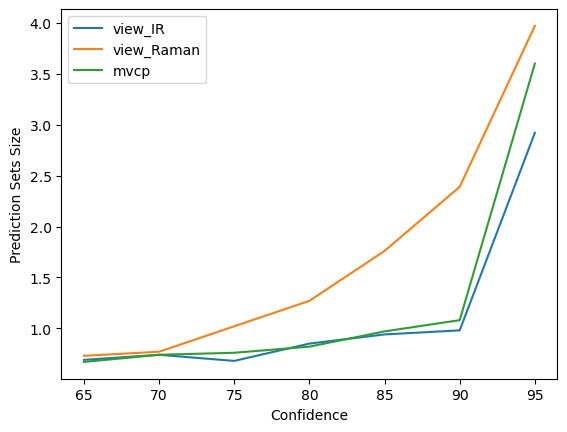

In [97]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

In [98]:
df_res_all = pd.concat(df_res_cov_lis, axis=0)*100
df_res_all['confidence'] = (1-alphas)*100 
np.round(df_res_all)

cp,view_IR,view_Raman,mvcp,confidence
0,99.0,98.0,98.0,95.0
0,95.0,93.0,94.0,90.0
0,93.0,90.0,91.0,85.0
0,83.0,82.0,81.0,80.0
0,68.0,84.0,76.0,75.0
0,73.0,68.0,73.0,70.0
0,68.0,65.0,65.0,65.0


In [150]:
alpha = .1
seed = 5
K = 2
quant_smx_list = []
rest_smx_list = []
cal_smx_list = []
val_smx_list = []
U_list = gen_u(K, seed=0)

for i in range(K):
    #quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed) 
    quant_smx, cal_smx, quant_labels, cal_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
    
    val_smx, y_val = score_list_rest[i], y_ir_rest
    
    #y_val = list(label_table.iloc[val_labels,1])
    
    y_val_ir = np.array(notes_mix_std_rest.loc[:,'polymer_ir'])
    y_val_raman = np.array(notes_mix_std_rest.loc[:,'polymer_raman'])
    comments_val = np.array(notes_mix_std_rest.loc[:,'comments'])
    
    quant_smx_list.append(quant_smx)
    #rest_smx_list.append(rest_smx)
    cal_smx_list.append(cal_smx)
    val_smx_list.append(val_smx)

n = cal_labels.shape[0]

prediction_sets = mvcp_2(quant_smx_list, 
                                             quant_labels,   
                                             cal_smx_list,   
                                             cal_labels,   
                                             val_smx_list,   
                                             alpha,     
                                             val_labels=None,                 
                                             U=U_list[0])


#s_u = rest_smx_list[0]

#cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
cal_smx, val_smx = cal_smx_list[0], val_smx_list[0]

n = cal_smx.shape[0]
prediction_sets_ir, qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, cond=0)


cal_smx, val_smx = cal_smx_list[1], val_smx_list[1]
n = cal_smx.shape[0]
prediction_sets_raman, qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, cond=0)


In [151]:
prediction_sets_raman[np.array(IR_spectra_amb_rest['polymer'] == "MIX"),:]

array([[False, False,  True, False, False, False, False],
       [ True,  True, False, False, False,  True, False],
       [False,  True, False, False,  True,  True, False],
       [False, False,  True,  True, False, False, False],
       [False, False,  True,  True,  True,  True, False],
       [ True,  True, False, False, False, False, False],
       [ True,  True, False, False, False, False, False],
       [ True,  True, False, False,  True,  True, False],
       [False, False,  True,  True, False, False, False],
       [False, False, False, False,  True, False, False],
       [False, False, False,  True, False,  True, False],
       [ True,  True, False, False, False, False, False],
       [False, False, False,  True,  True,  True, False],
       [False, False,  True,  True,  True, False, False],
       [ True,  True, False, False, False, False, False]])

In [152]:
prediction_sets_ir[np.array(IR_spectra_amb_rest['polymer'] == "MIX"),:]

array([[False, False,  True, False, False, False, False],
       [False, False, False, False, False,  True, False],
       [False, False, False, False, False,  True, False],
       [False, False,  True, False, False, False, False],
       [False, False, False, False,  True, False, False],
       [False, False, False, False, False,  True, False],
       [False, False, False, False, False,  True, False],
       [ True, False, False, False, False, False, False],
       [False, False, False,  True, False, False, False],
       [False, False, False, False,  True, False, False],
       [False, False, False,  True, False, False, False],
       [False, False, False, False, False,  True, False],
       [False, False, False,  True, False, False, False],
       [False, False,  True, False, False, False, False],
       [False, False, False, False,  True, False, False]])

In [153]:
prediction_sets[np.array(IR_spectra_amb_rest['polymer'] == "MIX"),:]

array([[False, False,  True, False, False, False, False],
       [False, False, False, False, False,  True, False],
       [False, False, False, False, False,  True, False],
       [False, False,  True, False, False, False, False],
       [False, False, False, False,  True, False, False],
       [False, False, False, False, False,  True, False],
       [False, False, False, False, False,  True, False],
       [ True, False, False, False, False, False, False],
       [False, False, False,  True, False, False, False],
       [False, False, False, False,  True, False, False],
       [False, False, False,  True, False, False, False],
       [False, False, False, False, False,  True, False],
       [False, False, False,  True, False, False, False],
       [False, False,  True, False, False, False, False],
       [False, False, False, False, False, False, False]])

In [128]:
IR_spectra_amb_rest.query('polymer == "MIX"')

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer,polymer_raman,polymer_ir,comments,id,background
14,-0.358446,-0.359727,-0.358107,-0.353267,-0.357023,-0.359331,-0.357215,-0.359919,-0.359949,-0.358559,...,0.167015,0.093002,0,0,MIX,MIX,MIX,LDPE AND PSL?,25,no_background
24,1.946675,1.779858,1.727269,1.898987,2.144428,2.427234,2.737166,2.894723,2.691717,2.536290,...,-0.671302,-1.089978,0,0,MIX,UNS,MIX,PSL AND AMB? FLUORESCENCE,41,no_background
30,-1.211266,-1.165781,-1.066222,-0.908659,-0.860479,-0.813142,-0.578228,-0.413751,-0.598604,-0.451796,...,-0.963437,-1.458474,0,0,MIX,LOW,MIX,AMB AND PSL?,47,no_background
38,-0.404472,-0.402192,-0.399720,-0.415237,-0.420790,-0.407168,-0.399291,-0.398361,-0.381428,-0.373530,...,-0.329299,-0.275037,0,0,MIX,MIX,MIX,PSL AND LDPE?,56,no_background
101,-0.729630,-0.709002,-0.701970,-0.708710,-0.707472,-0.696996,-0.691367,-0.693839,-0.690592,-0.683598,...,1.218952,1.074496,0,0,MIX,UNS,MIX,LDPE AND AMB? NOT ENOUGH PEAKS IN RAMAN,136,no_background
105,0.144970,0.248775,0.363981,0.473943,0.587794,0.688924,0.792244,0.926946,1.050607,1.177879,...,-0.530879,-0.557915,0,0,MIX,UNS,MIX,AMB AND LDPE? FLUORESCENCE,142,no_background
111,1.364888,1.609629,1.865255,2.067075,2.214826,2.325466,2.417376,2.513702,2.593263,2.655910,...,-0.471369,-0.470699,0,0,MIX,UNS,MIX,PSL AND AMB? FLUORESCENCE,150,no_background
116,1.187322,1.079097,1.022516,0.928708,0.796648,0.672421,0.581607,0.569217,0.599100,0.623185,...,-0.332646,-0.340056,0,0,MIX,UNS,MIX,PSL AND AMB? FLUORESCENCE,157,no_background
117,-0.434663,-0.436105,-0.435654,-0.434604,-0.434846,-0.435164,-0.435024,-0.433999,-0.432875,-0.430993,...,0.451304,0.342057,0,0,MIX,LDPE,MIX,LDPE AND AMB?,158,no_background
118,-0.473976,-0.473478,-0.469325,-0.481152,-0.493143,-0.506141,-0.511141,-0.489116,-0.456445,-0.416983,...,-0.428722,-0.506686,0,0,MIX,MIX,MIX,PSL AND AMB?,159,no_background


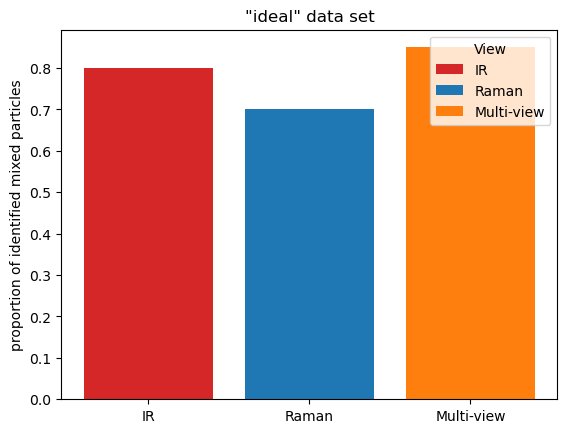

In [156]:
fig, ax = plt.subplots()

method = ['IR', 'Raman','Multi-view']#np.array(df_res_all.columns[:-1])
counts = [0.8, 0.7, 0.85]#np.array(df_res_all.iloc[0,:-1])
bar_labels = np.array(df_res_all.columns[:-1])
bar_colors = ['tab:red', 'tab:blue', 'tab:orange']

ax.bar(method, counts, label=method, color=bar_colors)

ax.set_ylabel('proportion of identified mixed particles')
ax.set_title('"ideal" data set')
ax.legend(title='View')

plt.show()

In [161]:
df_res_all

cp,view_IR,view_Raman,mvcp,confidence
0,99.166667,98.333333,98.333333,95.0
0,95.000000,93.333333,94.166667,90.0
0,93.333333,90.000000,90.833333,85.0
0,83.333333,82.500000,80.833333,80.0
0,68.333333,84.166667,75.833333,75.0
0,73.333333,67.500000,73.333333,70.0
0,67.500000,65.000000,65.000000,65.0


# Mix

In [172]:
mix_labels = ['PP', 'PE', 'PSL']

In [173]:
x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table = process_data(rebecca_data_ir.query('polymer in @mix_labels').reset_index(drop=True), 
                                                                                                     rebecca_data_raman.query('polymer in @mix_labels').reset_index(drop=True), 
                                                                                                     IR_spectra_mix, 
                                                                                                     Raman_spectra_mix)

x_ir_rest, x_raman_rest, y_ir_rest = process_data_2(IR_spectra_mix_rest, Raman_spectra_mix_rest)

In [174]:
smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman),1)
score_list = [smx_all_IR, smx_all_Raman]

In [175]:
smx_all_IR_rest = 1-np.power(smx_nn(x_train_ir, x_ir_rest, label_train_IR),1)
smx_all_Raman_rest = 1-np.power(smx_nn(x_train_raman, x_raman_rest, label_train_Raman),1)
score_list_rest = [smx_all_IR_rest, smx_all_Raman_rest]

In [176]:
np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_ir)

(0.8403908794788274, 0.8436482084690554)

In [177]:
df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis, df_res_all_lis = experiment(score_list, label_ir, alphas, N_sim, seed=0)


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 7/7 [00:08<00:00,  1.22s/it]


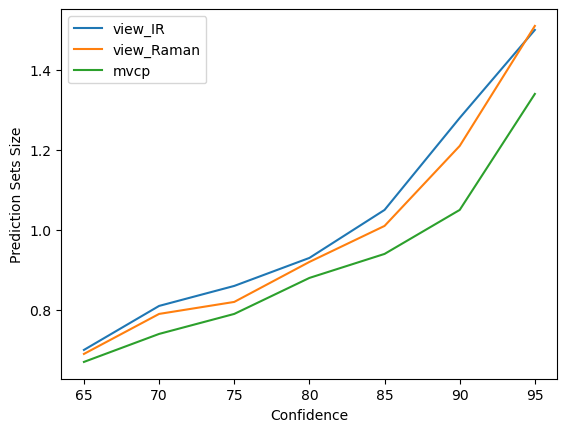

In [168]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

In [192]:
[x for x in df_res_all_lis[-1].keys()]

['mvcp2', 'view_IR2', 'view_Raman2', 'sum2', 'norm2']

In [193]:
[df_res_all_lis[-1][x] for x in df_res_all_lis[-1].keys()]

[[0.7, 0.72, 0.74, 0.68, 0.5, 0.64, 0.66, 0.76, 0.58, 0.7],
 [0.66, 0.56, 0.72, 0.76, 0.68, 0.74, 0.66, 0.76, 0.76, 0.7],
 [0.78, 0.7, 0.72, 0.7, 0.54, 0.72, 0.54, 0.82, 0.68, 0.68],
 [0.64, 0.54, 0.76, 0.74, 0.58, 0.66, 0.56, 0.68, 0.58, 0.76],
 [0.66, 0.54, 0.72, 0.74, 0.56, 0.68, 0.56, 0.74, 0.6, 0.76]]

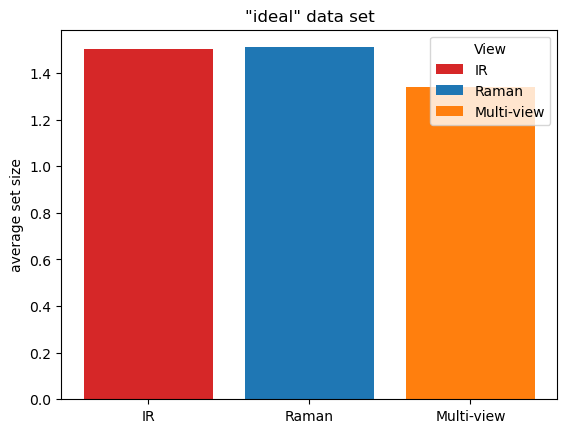

In [77]:
fig, ax = plt.subplots()

method = ['IR', 'Raman','Multi-view']#np.array(df_res_all.columns[:-1])
counts = np.array(df_res_all.iloc[0,:-1])
bar_labels = np.array(df_res_all.columns[:-1])
bar_colors = ['tab:red', 'tab:blue', 'tab:orange']

ax.bar(method, counts, label=method, color=bar_colors)

ax.set_ylabel('average set size')
ax.set_title('"ideal" data set')
ax.legend(title='View')

plt.show()

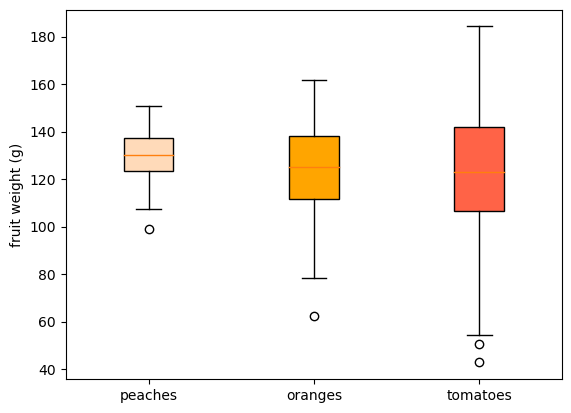

In [159]:
np.random.seed(19680801)
fruit_weights = [
    np.random.normal(130, 10, size=100),
    np.random.normal(125, 20, size=100),
    np.random.normal(120, 30, size=100),
]
labels = ['peaches', 'oranges', 'tomatoes']
colors = ['peachpuff', 'orange', 'tomato']

fig, ax = plt.subplots()
ax.set_ylabel('fruit weight (g)')

bplot = ax.boxplot(fruit_weights,
                   patch_artist=True,
                   labels=labels)  # will be used to label x-ticks

# fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.show()

In [37]:
#np.array(df_res_all.iloc[0,:-1])
df_res_all.columns[:-1]

Index(['view_IR', 'view_Raman', 'mvcp'], dtype='object', name='cp')

In [52]:
df_res_all = pd.concat(df_res_cov_lis, axis=0)*100
df_res_all['confidence'] = (1-alphas)*100
np.round(df_res_all)

cp,view_IR,view_Raman,mvcp,confidence
0,96.0,97.0,95.0,95.0
0,90.0,93.0,92.0,90.0
0,86.0,86.0,87.0,85.0
0,82.0,80.0,82.0,80.0
0,75.0,73.0,76.0,75.0
0,74.0,72.0,71.0,70.0
0,67.0,67.0,69.0,65.0


# Mix-Std

In [52]:
x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table = process_data(rebecca_data_ir, 
                                                                                                     rebecca_data_raman, 
                                                                                                     IR_spectra_mix_std, 
                                                                                                     Raman_spectra_mix_std)

x_ir_rest, x_raman_rest, y_ir_rest = process_data_2(IR_spectra_mix_std_rest, Raman_spectra_mix_std_rest)



In [53]:
[x.shape for x in [x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table]]

[(349, 525),
 (388, 1475),
 (349,),
 (388,),
 (224, 525),
 (224, 1475),
 (224,),
 (224,),
 (6, 2)]

In [54]:
smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman),1)
score_list = [smx_all_IR, smx_all_Raman]

In [55]:
smx_all_IR_rest = 1-np.power(smx_nn(x_train_ir, x_ir_rest, label_train_IR),1)
smx_all_Raman_rest = 1-np.power(smx_nn(x_train_raman, x_raman_rest, label_train_Raman),1)
score_list_rest = [smx_all_IR_rest, smx_all_Raman_rest]

In [56]:
np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_raman)

(0.84375, 0.8705357142857143)

In [63]:
alphas = np.arange(0.05,.2,.01)
N_sim = 10


In [64]:
df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis, df_res_all_lis = experiment(score_list, label_ir, alphas, N_sim, seed=0)


100%|███████████████████████████████████████████| 16/16 [00:09<00:00,  1.72it/s]


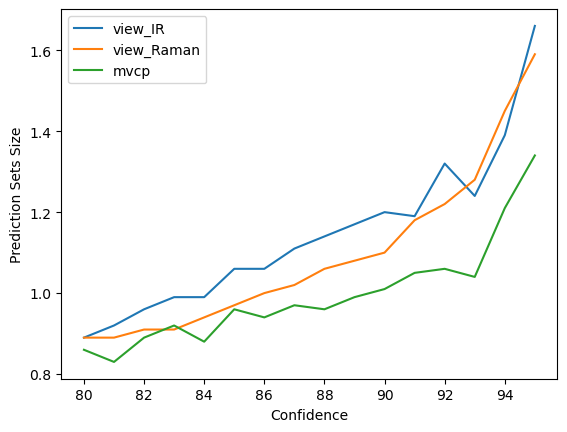

In [65]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

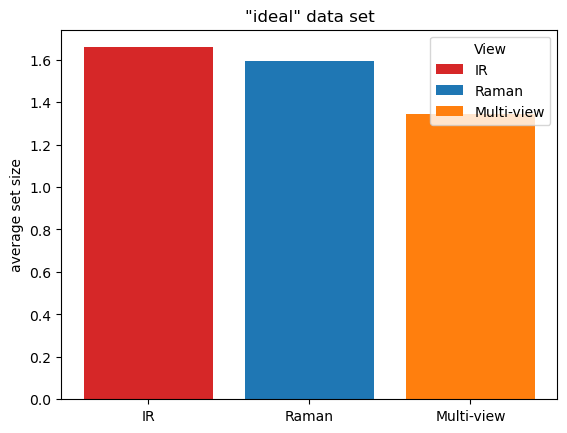

In [86]:
fig, ax = plt.subplots()

method = ['IR', 'Raman','Multi-view']#np.array(df_res_all.columns[:-1])
counts = np.array(df_res_all.iloc[0,:-1])
bar_labels = np.array(df_res_all.columns[:-1])
bar_colors = ['tab:red', 'tab:blue', 'tab:orange']

ax.bar(method, counts, label=method, color=bar_colors)

ax.set_ylabel('average set size')
ax.set_title('"ideal" data set')
ax.legend(title='View')

plt.show()

In [87]:
df_res_all = pd.concat(df_res_cov_lis, axis=0)*100
df_res_all['confidence'] = (1-alphas)*100
np.round(df_res_all)

cp,view_IR,view_Raman,mvcp,confidence
0,98.0,97.0,97.0,95.0
0,90.0,87.0,87.0,90.0
0,87.0,86.0,84.0,85.0
0,82.0,86.0,81.0,80.0
0,77.0,70.0,75.0,75.0
0,73.0,75.0,73.0,70.0
0,64.0,73.0,67.0,65.0


In [88]:
alpha = .05
seed = 1
K = 2
quant_smx_list = []
rest_smx_list = []
cal_smx_list = []
val_smx_list = []
U_list = gen_u(K, seed=0)

for i in range(K):
    quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
    cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=0.8, seed=seed)
    
    y_val = list(label_table.iloc[val_labels,1])
    
    y_val_ir = np.array(notes_mix_std.loc[~idx_quant,:].loc[~idx,'polymer_ir'])
    y_val_raman = np.array(notes_mix_std.loc[~idx_quant,:].loc[~idx,'polymer_raman'])
    
    quant_smx_list.append(quant_smx)
    rest_smx_list.append(rest_smx)
    cal_smx_list.append(cal_smx)
    val_smx_list.append(val_smx)

n = cal_labels.shape[0]

prediction_sets, empirical_coverage = mvcp_2(quant_smx_list, 
                                             quant_labels,   
                                             cal_smx_list,   
                                             cal_labels,   
                                             val_smx_list,   
                                             alpha,     
                                             val_labels,                 
                                             U=U_list[0])


In [89]:
prediction_sets.sum(1).mean()

1.0833333333333333

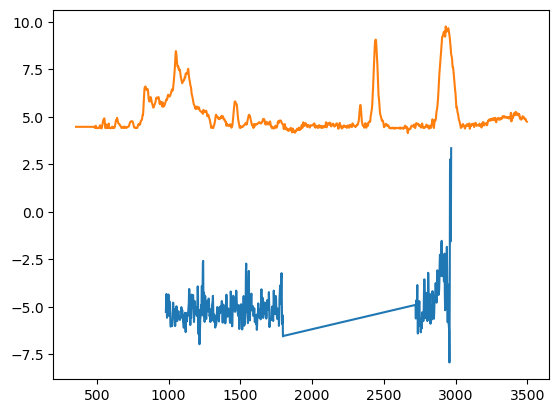

In [119]:
plt.plot(IR_spectra_mix_std.loc[~idx_quant,:].loc[~idx,:].loc[y_val_ir == 'LOW SIGNAL',:].iloc[2,:-5]-5)
plt.plot(Raman_spectra_mix_std.loc[~idx_quant,:].loc[~idx,:].loc[y_val_ir == 'LOW SIGNAL',:].iloc[2,:-5]+5)

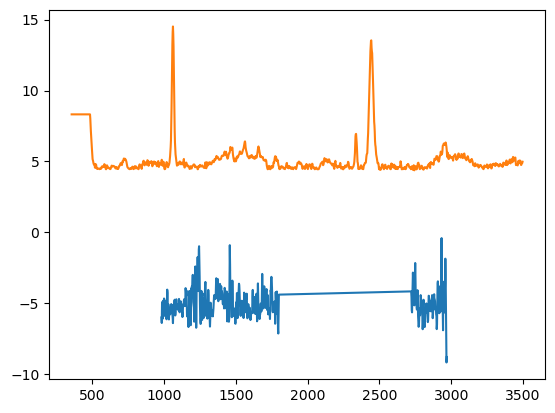

In [148]:
plt.plot(IR_spectra_mix_std.loc[~idx_quant,:].loc[~idx,:].loc[y_val_ir == 'LOW SIGNAL',:].iloc[-3,:-5]-5)
plt.plot(Raman_spectra_mix_std.loc[~idx_quant,:].loc[~idx,:].loc[y_val_ir == 'LOW SIGNAL',:].iloc[-3,:-5]+5)

In [121]:
IR_spectra_mix_std.loc[~idx_quant,:].loc[~idx,:].loc[y_val_ir == 'LOW SIGNAL',:].iloc[[2,-3],:]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,polymer,id,background
81,-0.264859,0.257357,0.681966,-0.055727,-0.568173,-0.088574,0.222945,-0.218250,0.023277,0.655452,...,7.200979,7.763641,3.444022,3.556771,8.347582,0,0,sucrose,156,no_background
146,-1.008692,-1.399738,0.068856,-0.006679,-1.101531,-1.031901,0.173746,0.063854,-0.192763,0.325479,...,2.018562,0.166318,-2.395374,-4.186569,-3.798224,0,0,NaNO3,246,background


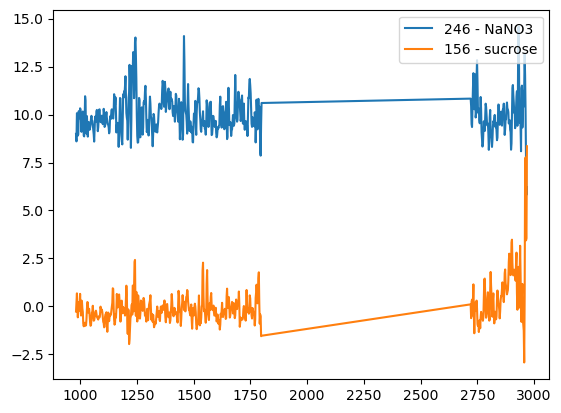

In [153]:
_ = plt.plot(IR_spectra_mix_std.loc[~idx_quant,:].loc[~idx,:].loc[y_val_ir == 'LOW SIGNAL',:].iloc[-3,:-5].T+10, label='246 - NaNO3')
_ = plt.plot(IR_spectra_mix_std.loc[~idx_quant,:].loc[~idx,:].loc[y_val_ir == 'LOW SIGNAL',:].iloc[2,:-5].T, label='156 - sucrose')
_ = plt.legend(loc='upper right')

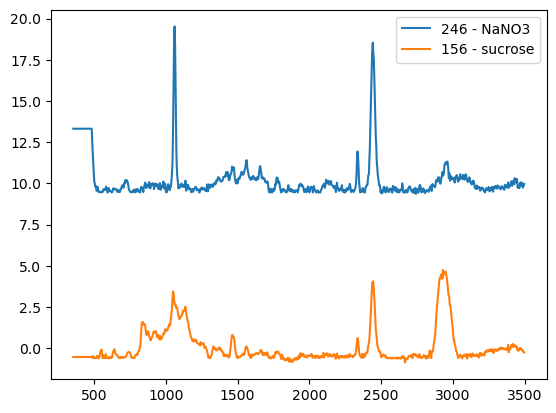

In [154]:
_ = plt.plot(Raman_spectra_mix_std.loc[~idx_quant,:].loc[~idx,:].loc[y_val_ir == 'LOW SIGNAL',:].iloc[-3,:-5].T+10, label='246 - NaNO3')
_ = plt.plot(Raman_spectra_mix_std.loc[~idx_quant,:].loc[~idx,:].loc[y_val_ir == 'LOW SIGNAL',:].iloc[2,:-5].T, label='156 - sucrose')
_ = plt.legend()

In [123]:
#pd.DataFrame({'y_val':y_val,
#              'y_val_ir':y_val_ir,
#              'y_val_raman':y_val_raman})

In [126]:
prediction_sets_n = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])
print(np.mean([y in x for x, y in zip(prediction_sets_n, y_val)]),
      prediction_sets.sum(1).mean())
[(i, x,y, z, w) for i, (x, y, z, w) in enumerate(zip(prediction_sets_n, y_val, y_val_ir, y_val_raman)) if z == 'LOW SIGNAL']


1.0 1.0833333333333333


[(5, ['NH2SO4'], 'NH2SO4', 'LOW SIGNAL', 'NH2SO4'),
 (7, ['PP', 'sucrose'], 'sucrose', 'LOW SIGNAL', 'sucrose'),
 (11, ['sucrose'], 'sucrose', 'LOW SIGNAL', 'sucrose'),
 (14, ['sucrose'], 'sucrose', 'LOW SIGNAL', 'sucrose'),
 (19, ['NH2SO4', 'sucrose'], 'NH2SO4', 'LOW SIGNAL', 'NH2SO4'),
 (23, ['NaNO3', 'sucrose'], 'NaNO3', 'LOW SIGNAL', 'NaNO3'),
 (31, ['sucrose'], 'sucrose', 'LOW SIGNAL', 'sucrose'),
 (32, ['sucrose'], 'sucrose', 'LOW SIGNAL', 'sucrose')]

In [133]:
print('156 - MVPC prediction set:', prediction_sets_n[7])
print('246 - MVPC prediction set:', prediction_sets_n[23])

156 - MVPC prediction set: ['PP', 'sucrose']
246 - MVPC prediction set: ['NaNO3', 'sucrose']


In [134]:
s_u = rest_smx_list[0]

cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
n = cal_smx.shape[0]
(prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
                

In [135]:
prediction_sets_n = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])
print(np.mean([y in x for x, y in zip(prediction_sets_n, y_val)]),
      prediction_sets.sum(1).mean())
[(i, x,y, z, w) for i, (x, y, z, w) in enumerate(zip(prediction_sets_n, y_val, y_val_ir, y_val_raman)) if z == 'LOW SIGNAL']


1.0 1.5277777777777777


[(5, ['NH2SO4', 'PE', 'sucrose'], 'NH2SO4', 'LOW SIGNAL', 'NH2SO4'),
 (7,
  ['NH2SO4', 'NaNO3', 'PP', 'PSL', 'sucrose'],
  'sucrose',
  'LOW SIGNAL',
  'sucrose'),
 (11,
  ['NH2SO4', 'PE', 'PP', 'PSL', 'sucrose'],
  'sucrose',
  'LOW SIGNAL',
  'sucrose'),
 (14, ['sucrose'], 'sucrose', 'LOW SIGNAL', 'sucrose'),
 (19, ['NH2SO4', 'sucrose'], 'NH2SO4', 'LOW SIGNAL', 'NH2SO4'),
 (23,
  ['NH2SO4', 'NaNO3', 'PP', 'PSL', 'sucrose'],
  'NaNO3',
  'LOW SIGNAL',
  'NaNO3'),
 (31, ['NH2SO4', 'sucrose'], 'sucrose', 'LOW SIGNAL', 'sucrose'),
 (32, ['PP', 'sucrose'], 'sucrose', 'LOW SIGNAL', 'sucrose')]

In [136]:
print('156 - IRCP prediction set:', prediction_sets_n[7])
print('246 - IRCP prediction set:', prediction_sets_n[23])

156 - IRCP prediction set: ['NH2SO4', 'NaNO3', 'PP', 'PSL', 'sucrose']
246 - IRCP prediction set: ['NH2SO4', 'NaNO3', 'PP', 'PSL', 'sucrose']


In [137]:
s_u = rest_smx_list[1]

cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
n = cal_smx.shape[0]
(prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
                

In [138]:
prediction_sets_n = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])
print(np.mean([y in x for x, y in zip(prediction_sets_n, y_val)]),
      prediction_sets.sum(1).mean())
[(i, x,y, z, w) for i, (x, y, z, w) in enumerate(zip(prediction_sets_n, y_val, y_val_ir, y_val_raman)) if z == 'LOW SIGNAL']

1.0 1.3611111111111112


[(5, ['NH2SO4'], 'NH2SO4', 'LOW SIGNAL', 'NH2SO4'),
 (7, ['PP', 'sucrose'], 'sucrose', 'LOW SIGNAL', 'sucrose'),
 (11, ['sucrose'], 'sucrose', 'LOW SIGNAL', 'sucrose'),
 (14, ['sucrose'], 'sucrose', 'LOW SIGNAL', 'sucrose'),
 (19,
  ['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'],
  'NH2SO4',
  'LOW SIGNAL',
  'NH2SO4'),
 (23, ['NaNO3', 'PSL', 'sucrose'], 'NaNO3', 'LOW SIGNAL', 'NaNO3'),
 (31, ['sucrose'], 'sucrose', 'LOW SIGNAL', 'sucrose'),
 (32, ['sucrose'], 'sucrose', 'LOW SIGNAL', 'sucrose')]

In [140]:
print('156 - RamanCP prediction set:', prediction_sets_n[7])
print('246 - RamanCP prediction set:', prediction_sets_n[23])

156 - RamanCP prediction set: ['PP', 'sucrose']
246 - RamanCP prediction set: ['NaNO3', 'PSL', 'sucrose']


In [317]:
alpha = .05
seed = 5
K = 2
quant_smx_list = []
rest_smx_list = []
cal_smx_list = []
val_smx_list = []
U_list = gen_u(K, seed=0)

for i in range(K):
    #quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed) 
    quant_smx, cal_smx, quant_labels, cal_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
    
    val_smx, y_val = score_list_rest[i], y_ir_rest
    
    #y_val = list(label_table.iloc[val_labels,1])
    
    y_val_ir = np.array(notes_mix_std_rest.loc[:,'polymer_ir'])
    y_val_raman = np.array(notes_mix_std_rest.loc[:,'polymer_raman'])
    comments_val = np.array(notes_mix_std_rest.loc[:,'comments'])
    
    quant_smx_list.append(quant_smx)
    #rest_smx_list.append(rest_smx)
    cal_smx_list.append(cal_smx)
    val_smx_list.append(val_smx)

n = cal_labels.shape[0]

prediction_sets = mvcp_2(quant_smx_list, 
                                             quant_labels,   
                                             cal_smx_list,   
                                             cal_labels,   
                                             val_smx_list,   
                                             alpha,     
                                             val_labels=None,                 
                                             U=U_list[0])


In [339]:
prediction_sets_n = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])
print(#np.mean([y in x for x, y in zip(prediction_sets_n, y_val)]),
      prediction_sets.sum(1).mean())
#[(i, x,y, z, w) for i, (x, y, z, w) in enumerate(zip(prediction_sets_n, y_val, y_val_ir, y_val_raman))]
[(i, x,y, z, w, c) for i, (x, y, z, w, c) in enumerate(zip(prediction_sets_n, y_val, y_val_ir, y_val_raman,comments_val)) if type(c) is str]


1.6585365853658536


[(3, ['PSL'], 'LOW SIGNAL', 'MIXTURE', 'PSL', 'PSL AND SOMETHING ELSE? SCR?'),
 (6, ['NH2SO4'], 'LOW SIGNAL', 'NH2SO4', 'MIXTURE', 'AS AND LDPE?'),
 (8, ['PE', 'PP'], 'LOW SIGNAL', 'MIXTURE', 'MIXTURE', 'PP AND LDPE?'),
 (9,
  ['NaNO3', 'PE', 'sucrose'],
  'LOW SIGNAL',
  'LOW SIGNAL',
  'UNSORTED',
  'FLUORESCENCE, LDPE?'),
 (10, ['PE'], 'LOW SIGNAL', 'UNSORTED', 'PE', 'ODD PEAKS IN PTIR'),
 (11,
  ['NH2SO4', 'NaNO3', 'PE', 'PP', 'sucrose'],
  'LOW SIGNAL',
  'LOW SIGNAL',
  'MIXTURE',
  'SCR AND SN?'),
 (12,
  ['sucrose'],
  'LOW SIGNAL',
  'UNSORTED',
  'UNSORTED',
  'PEAKS UNIDENTIFIED, MIX?'),
 (13,
  ['NH2SO4', 'NaNO3', 'PE', 'PP', 'sucrose'],
  'LOW SIGNAL',
  'LOW SIGNAL',
  'UNSORTED',
  'FLUORESCENCE'),
 (14,
  ['NaNO3', 'sucrose'],
  'LOW SIGNAL',
  'LOW SIGNAL',
  'UNSORTED',
  'FLUORESCENCE'),
 (15,
  ['NH2SO4', 'NaNO3', 'sucrose'],
  'LOW SIGNAL',
  'UNSORTED',
  'UNSORTED',
  'ODD PEAKS IN PTIR, FLUORESCENCE'),
 (18,
  ['NH2SO4', 'NaNO3', 'PE', 'PSL', 'sucrose'],
  'LOW 

In [346]:
cal_smx, val_smx = cal_smx_list[0], val_smx_list[0]
n = cal_smx.shape[0]
prediction_sets, qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels=None, cond=0) 

In [347]:
prediction_sets_n = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])
print(#np.mean([y in x for x, y in zip(prediction_sets_n, y_val)]),
      prediction_sets.sum(1).mean())
#[(i, x,y, z, w) for i, (x, y, z, w) in enumerate(zip(prediction_sets_n, y_val, y_val_ir, y_val_raman))]
[(i, x,y, z, w, c) for i, (x, y, z, w, c) in enumerate(zip(prediction_sets_n, y_val, y_val_ir, y_val_raman,comments_val)) if type(c) is str]


3.131707317073171


[(3,
  ['NH2SO4', 'NaNO3', 'sucrose'],
  'LOW SIGNAL',
  'MIXTURE',
  'PSL',
  'PSL AND SOMETHING ELSE? SCR?'),
 (6,
  ['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'NH2SO4',
  'MIXTURE',
  'AS AND LDPE?'),
 (8,
  ['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'MIXTURE',
  'MIXTURE',
  'PP AND LDPE?'),
 (9,
  ['NH2SO4', 'NaNO3', 'PP', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'LOW SIGNAL',
  'UNSORTED',
  'FLUORESCENCE, LDPE?'),
 (10,
  ['NH2SO4', 'NaNO3', 'PP', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'UNSORTED',
  'PE',
  'ODD PEAKS IN PTIR'),
 (11,
  ['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'LOW SIGNAL',
  'MIXTURE',
  'SCR AND SN?'),
 (12,
  ['NH2SO4', 'NaNO3', 'PE', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'UNSORTED',
  'UNSORTED',
  'PEAKS UNIDENTIFIED, MIX?'),
 (13,
  ['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'LOW SIGNAL',
  'UNSORTED',
  'FLUORESCENCE'),
 (14,
  ['NH2SO4', 'NaNO3', 'PE', 'PP'

In [348]:
cal_smx, val_smx = cal_smx_list[1], val_smx_list[1]
n = cal_smx.shape[0]
prediction_sets, qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels=None, cond=0) 

In [349]:
prediction_sets_n = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])
print(#np.mean([y in x for x, y in zip(prediction_sets_n, y_val)]),
      prediction_sets.sum(1).mean())
#[(i, x,y, z, w) for i, (x, y, z, w) in enumerate(zip(prediction_sets_n, y_val, y_val_ir, y_val_raman))]
[(i, x,y, z, w, c) for i, (x, y, z, w, c) in enumerate(zip(prediction_sets_n, y_val, y_val_ir, y_val_raman,comments_val)) if type(c) is str]


2.1121951219512196


[(3, ['PSL'], 'LOW SIGNAL', 'MIXTURE', 'PSL', 'PSL AND SOMETHING ELSE? SCR?'),
 (6, ['NH2SO4'], 'LOW SIGNAL', 'NH2SO4', 'MIXTURE', 'AS AND LDPE?'),
 (8, ['PE', 'PP'], 'LOW SIGNAL', 'MIXTURE', 'MIXTURE', 'PP AND LDPE?'),
 (9,
  ['NaNO3', 'PE', 'sucrose'],
  'LOW SIGNAL',
  'LOW SIGNAL',
  'UNSORTED',
  'FLUORESCENCE, LDPE?'),
 (10, ['PE'], 'LOW SIGNAL', 'UNSORTED', 'PE', 'ODD PEAKS IN PTIR'),
 (11,
  ['NH2SO4', 'NaNO3', 'PE', 'PP', 'sucrose'],
  'LOW SIGNAL',
  'LOW SIGNAL',
  'MIXTURE',
  'SCR AND SN?'),
 (12,
  ['sucrose'],
  'LOW SIGNAL',
  'UNSORTED',
  'UNSORTED',
  'PEAKS UNIDENTIFIED, MIX?'),
 (13,
  ['NH2SO4', 'NaNO3', 'PE', 'PP', 'sucrose'],
  'LOW SIGNAL',
  'LOW SIGNAL',
  'UNSORTED',
  'FLUORESCENCE'),
 (14,
  ['NaNO3', 'sucrose'],
  'LOW SIGNAL',
  'LOW SIGNAL',
  'UNSORTED',
  'FLUORESCENCE'),
 (15,
  ['NH2SO4', 'NaNO3', 'sucrose'],
  'LOW SIGNAL',
  'UNSORTED',
  'UNSORTED',
  'ODD PEAKS IN PTIR, FLUORESCENCE'),
 (18,
  ['NH2SO4', 'NaNO3', 'PE', 'PSL', 'sucrose'],
  'LOW 